# 04 · EUR and GBP, and the cross-currency comparison

Notebooks 01–03 built and tested the models on USD. This notebook runs the
same pipeline on the euro area (ECB AAA government curve) and the UK (Bank
of England nominal government curve), and compares all three on a common
out-of-sample window (README §8, step 7).

What differs from USD:

- **Shorter samples.** The ECB curve starts in Sep 2004. EUR models are
  estimated from 2004-09 and GBP from **1993-01**: inflation targeting
  started in Oct 1992, and from 1985 the Bank Rate disinflation pushes the
  estimated VAR to a unit root (§1). Forecast origins start in **2010-01**
  for both, which is the common window used for USD in §5 as well.
- **GBP short-end gaps.** The BoE does not publish its 3m point in 305 of
  the 502 months since 1985 (6m: 99). Nothing is filled in. The Kalman
  filter drops the missing rows each month (README §5.2), which is the
  case this design was built for.
- **No real-time vintages.** EUR and GBP macro data use the latest
  vintage, with the last `release_lag_months` (activity 2, inflation 1)
  blanked at each origin (README §7.3). Revisions are therefore ignored:
  a limitation, though notebook 03 found inflation revisions small.
- **Macro series:** industrial production (y/y), HICP / CPI inflation, and the
  ECB deposit facility rate / Bank Rate.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from yck.data.realtime import RealTimeMacro
from yck.model.dns import fit_factors, ns_loadings, maturities_from_columns
from yck.model.statespace_dns import fit_dns_mle, score
from yck.model.kalman import smoothed_stats
from yck.model import irf
from yck.eval.backtest import dns_two_step_forecasts, random_walk_forecasts, forward_forecasts
from yck.eval.grid import ensure_results
from yck.eval.stats import dm_table, cw_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG = ROOT / "data/results", ROOT / "config/data_sources.yaml"
CCYS = ["USD", "EUR", "GBP"]
EST_START = {"USD": "1985-01-31", "EUR": "2004-09-30", "GBP": "1993-01-31"}
FIRST_ORIGIN = {"USD": "2000-01-31", "EUR": "2010-01-31", "GBP": "2010-01-31"}
COMMON = "2010-01-31"  # first origin of the cross-currency comparison
H = (1, 6, 12)
MACRO = ["real_activity", "inflation", "policy_rate"]
SHOW = {"USD": ["3m", "12m", "24m", "60m", "120m"], "EUR": ["3m", "12m", "24m", "60m", "120m"],
        "GBP": ["6m", "12m", "24m", "60m", "120m"]}  # GBP 3m: 39 published months since 2010 (§4)
SHOW_COMMON = ["6m", "12m", "24m", "60m", "120m"]  # cross-currency comparison (§5)
LABEL = {"level": "level", "slope": "slope", "curvature": "curvature", "real_activity": "activity",
         "inflation": "inflation", "policy_rate": "policy rate"}

y = {c: pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet").loc[EST_START[c]:] for c in CCYS}
macro = {c: pd.read_parquet(ROOT / f"data/processed/macro_{c}.parquet") for c in CCYS}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.DataFrame({c: {"first month": f"{y[c].index[0]:%Y-%m}", "months": len(y[c]),
                  "missing 3m": int(y[c]["3m"].isna().sum()), "missing 6m": int(y[c]["6m"].isna().sum())}
              for c in CCYS})

,USD,EUR,GBP
first month,1985-01,2004-09,1993-01
months,502,266,406
missing 3m,0,0,215
missing 6m,0,0,73


## 1. The data

Top: the 3m and 10y yields and the policy rate. Bottom: real activity and
inflation. The industrial-production growth rates have COVID swings of
±20–40%, far outside anything else in the samples. A Gaussian VAR treats
them as huge shocks, and they inflate the activity shock variance.

The grey ticks mark months with no BoE 3m yield.

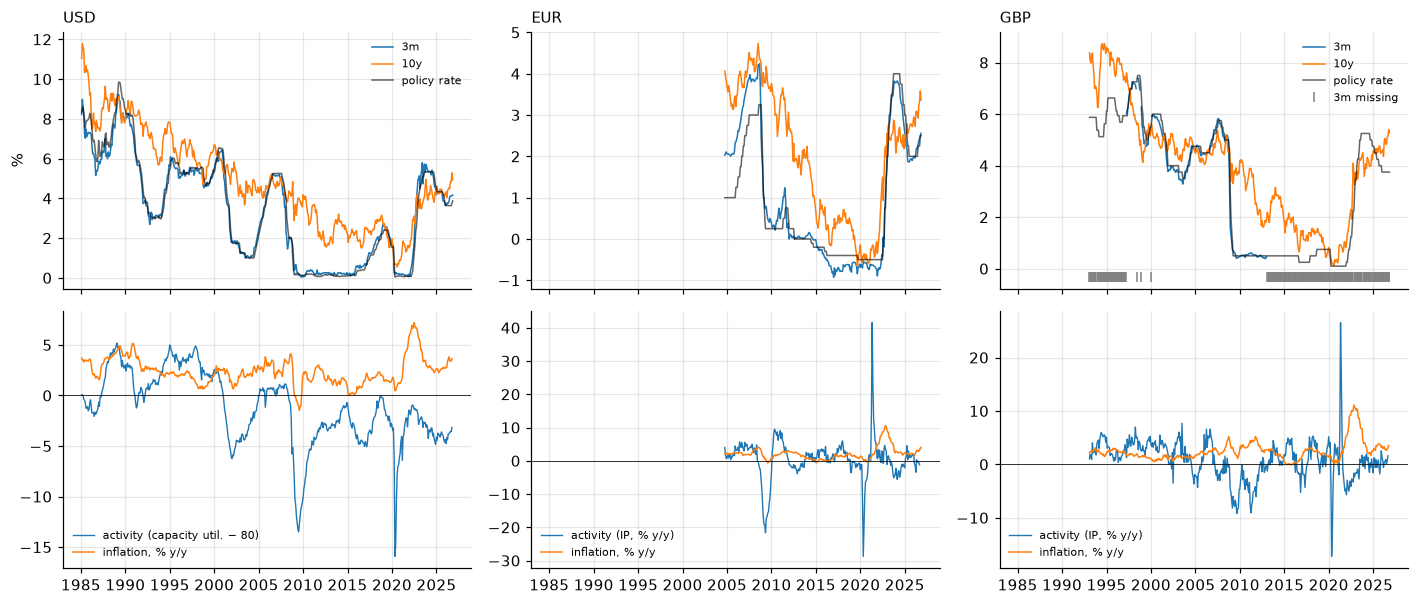

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True)
for j, c in enumerate(CCYS):
    ax = axes[0, j]
    ax.plot(y[c]["3m"], lw=1, label="3m"); ax.plot(y[c]["120m"], lw=1, label="10y")
    ax.plot(macro[c]["policy_rate"].loc[EST_START[c]:], lw=1, color="k", alpha=0.6, label="policy rate")
    if y[c]["3m"].isna().any():
        miss = y[c].index[y[c]["3m"].isna()]
        ax.plot(miss, np.full(len(miss), ax.get_ylim()[0]), "|", color="0.5", ms=6, label="3m missing")
    ax.set_title(c, loc="left", fontsize=10); ax.set_ylabel("%" if j == 0 else "")
    ax2 = axes[1, j]
    m = macro[c].loc[EST_START[c]:]
    act, lab = (m["real_activity"] - 80, "capacity util. − 80") if c == "USD" else (m["real_activity"], "IP, % y/y")
    ax2.plot(act, lw=0.9, label=f"activity ({lab})")
    ax2.plot(m["inflation"], lw=1, label="inflation, % y/y")
    ax2.axhline(0, color="k", lw=0.5)
    ax2.legend(fontsize=7, frameon=False, loc="lower left")
axes[0, 0].legend(fontsize=7, frameon=False); axes[0, 2].legend(fontsize=7, frameon=False, loc="upper right")
fig.tight_layout()

## 2. Yields-only model, full sample

ML DNS with λ fixed at 0.0609 and the 1 bp noise floor, as for USD.
For GBP the filter sees, each month, only the maturities the BoE published.
Even so, it produces a model-implied 3m yield every month (`Z a_{t|t}`), shown
below where the BoE published none.

In [3]:
fits_y = {c: fit_dns_mle(y[c], n_starts=6) for c in CCYS}
pd.DataFrame({c: {"log-likelihood": round(f.loglik, 1), "μ (level, slope, curv.)": np.round(f.params.mu, 2),
                  "max |eig(A)|": round(float(np.max(np.abs(np.linalg.eigvals(f.params.A)))), 4),
                  "maturities at 1 bp floor": int((f.params.h <= 1.0001e-4).sum()),
                  "noise sd 3m / 10y (bp)": np.round(100 * np.sqrt(f.params.h[[0, -1]]), 1)}
              for c, f in fits_y.items()})

,USD,EUR,GBP
log-likelihood,13284.0,6900.8,11005.2
"μ (level, slope, curv.)","[5.4, -1.92, -2.09]","[2.41, -1.32, -2.21]","[4.36, -1.16, -1.56]"
max |eig(A)|,0.9932,0.983,0.9944
maturities at 1 bp floor,6,6,6
noise sd 3m / 10y (bp),"[19.1, 14.1]","[19.9, 15.0]","[28.8, 12.8]"


Where the 3m is published, filtered fit error: RMSE 28.5 bp
Model 3m minus Bank Rate, months without a BoE 3m: mean -7 bp


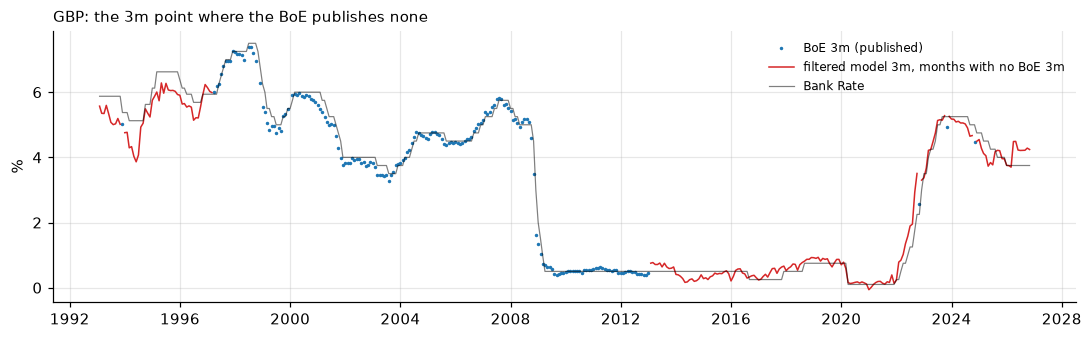

In [4]:
g = fits_y["GBP"]
ff = g.filtered_factors(y["GBP"])
implied = pd.DataFrame(ff[["level", "slope", "curvature"]].to_numpy() @ ns_loadings([3, 6, 12], g.params.lam).T,
                       index=ff.index, columns=["3m", "6m", "12m"])
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(y["GBP"]["3m"], ".", ms=2.5, label="BoE 3m (published)")
ax.plot(implied["3m"].where(y["GBP"]["3m"].isna()), lw=1, color="C3", label="filtered model 3m, months with no BoE 3m")
ax.plot(macro["GBP"]["policy_rate"].loc[EST_START["GBP"]:], lw=0.8, color="k", alpha=0.5, label="Bank Rate")
ax.set_ylabel("%"); ax.legend(fontsize=8, frameon=False); ax.set_title("GBP: the 3m point where the BoE publishes none", loc="left", fontsize=10)
obs = y["GBP"]["3m"].notna()
print(f"Where the 3m is published, filtered fit error: RMSE {100 * np.sqrt(((implied['3m'] - y['GBP']['3m'])[obs]**2).mean()):.1f} bp")
print(f"Model 3m minus Bank Rate, months without a BoE 3m: mean {100 * (implied['3m'] - macro['GBP']['policy_rate']).reindex(implied.index)[~obs].mean():.0f} bp")

## 3. Yields + macro, full sample: impulse responses and variance decompositions

The same identification as USD (Cholesky: activity, inflation, policy rate,
then level, slope, curvature). Below are the responses to the three macro shocks, and
the curve's effect on the policy rate, for all three currencies. Bands are
90% from the MLE's asymptotic distribution.

Note on convergence: for EUR and GBP the optimiser's raw gradient is
not tiny at the optimum (up to ~4 log-likelihood units per unit parameter),
because the coefficients on industrial-production growth are badly scaled
(its COVID swings make the likelihood extremely curved in them). The
Newton decrement, the log-likelihood still to gain, is below 0.002 in every
case (table below), so the fits are at their optimum. As for USD, μ is fixed
at the sample mean (README §6.3).

In [5]:
data_m = {c: y[c].join(macro[c][MACRO], how="left") for c in CCYS}
fits_m = {c: fit_dns_mle(data_m[c], n_starts=6) for c in CCYS}
draws = {c: irf.irf_draws(f, data_m[c], horizon=60, n_draws=1000) for c, f in fits_m.items()}

def newton_decrement(fit, data, info):
    # log-likelihood still to gain from a Newton step: g' (-H)^-1 g / 2
    tau = maturities_from_columns(fit.yield_columns)
    st = smoothed_stats(fit.params.statespace(tau), data[fit.columns].to_numpy(float))
    g = score(info.theta, st, tau)[info.free]
    return 0.5 * g @ info.cov @ g, np.abs(g).max()

summ = {}
for c, f in fits_m.items():
    dec, gmax = newton_decrement(f, data_m[c], draws[c].info)
    summ[c] = {"log-likelihood": round(f.loglik, 1), "max |gradient|": round(gmax, 3), "Newton decrement": f"{dec:.1e}",
               "max |eig(A)|": round(float(np.max(np.abs(np.linalg.eigvals(f.params.A)))), 4),
               "explosive draws / 1000": draws[c].n_rejected, "Hessian eigenvalues clipped": draws[c].info.n_clipped}
pd.DataFrame(summ)

,USD,EUR,GBP
log-likelihood,13121.7,6399.8,10346.9
max |gradient|,0.167,3.842,0.536
Newton decrement,1.4e-04,1.7e-03,2.3e-04
max |eig(A)|,0.9932,0.9698,0.985
explosive draws / 1000,210,104,161
Hessian eigenvalues clipped,0,0,0


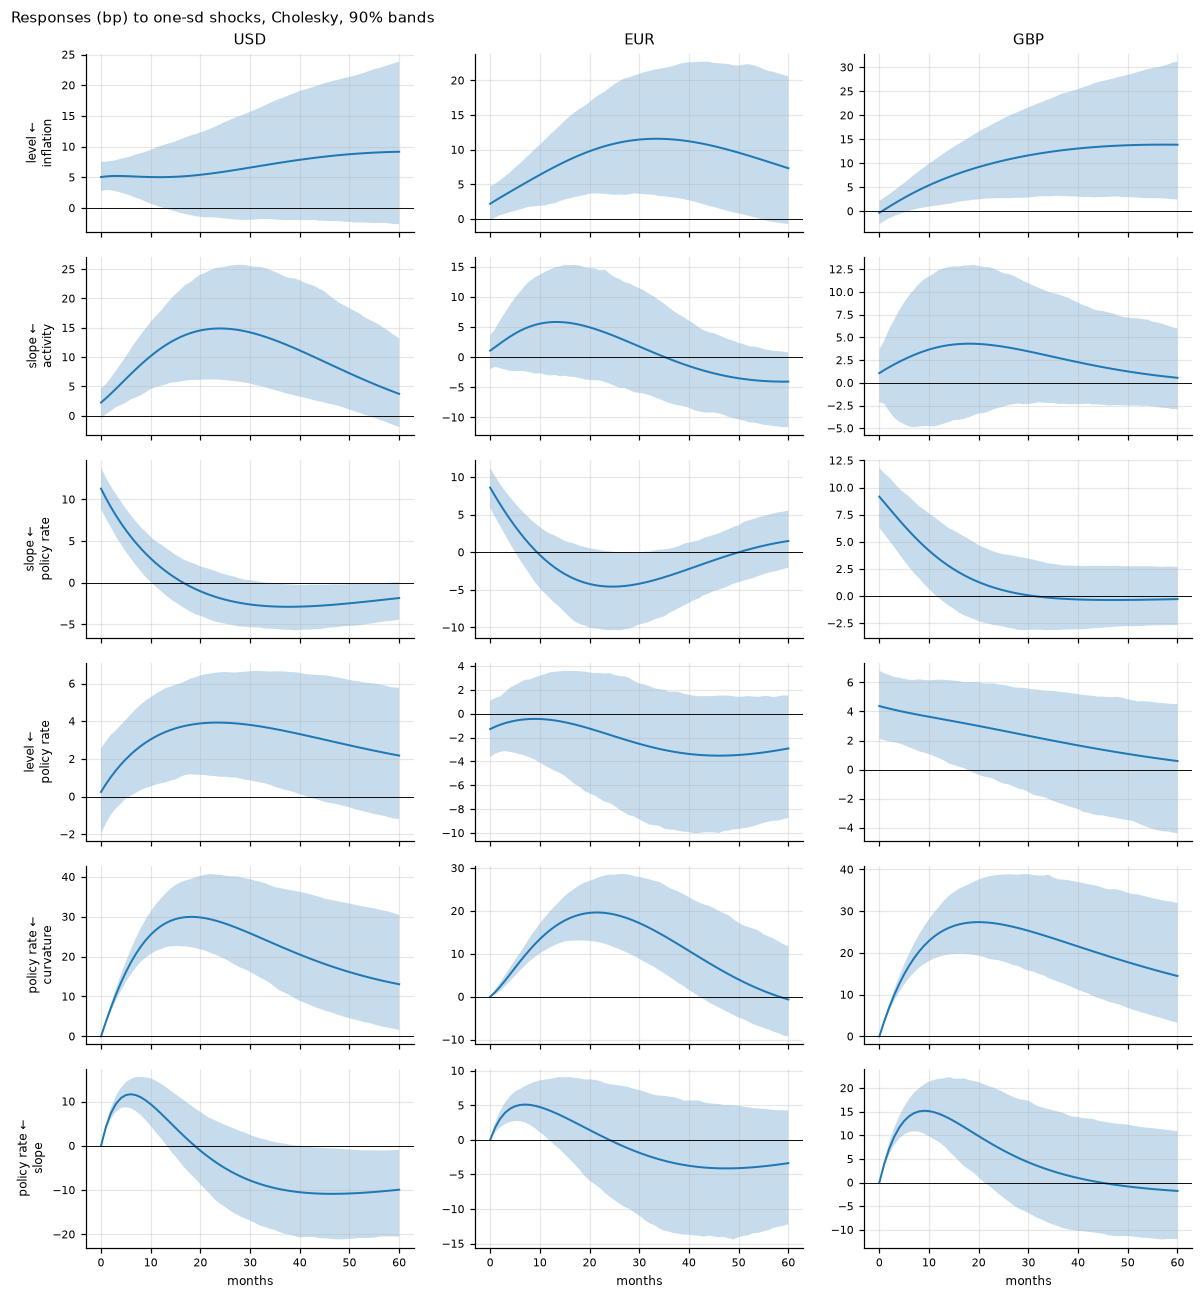

In [6]:
PAIRS = [("level", "inflation"), ("slope", "real_activity"), ("slope", "policy_rate"),
         ("level", "policy_rate"), ("policy_rate", "curvature"), ("policy_rate", "slope")]
fig, axes = plt.subplots(len(PAIRS), 3, figsize=(11, 2.0 * len(PAIRS)), sharex=True)
for r, (resp, shock) in enumerate(PAIRS):
    for j, c in enumerate(CCYS):
        d, names, ax = draws[c], fits_m[c].state_names, axes[r, j]
        i, k = names.index(resp), names.index(shock)
        lo, hi = d.band(0.9)
        hh = np.arange(d.point.shape[0])
        ax.fill_between(hh, 100 * lo[:, i, k], 100 * hi[:, i, k], alpha=0.25, lw=0)
        ax.plot(hh, 100 * d.point[:, i, k], lw=1.3); ax.axhline(0, color="k", lw=0.6)
        ax.tick_params(labelsize=7)
        if r == 0: ax.set_title(c, fontsize=10)
        if j == 0: ax.set_ylabel(f"{LABEL[resp]} ←\n{LABEL[shock]}", fontsize=8)
for ax in axes[-1]: ax.set_xlabel("months", fontsize=8)
fig.suptitle("Responses (bp) to one-sd shocks, Cholesky, 90% bands", x=0.01, ha="left", fontsize=10)
fig.tight_layout()

In [7]:
rows = {}
for c in CCYS:
    f = fits_m[c]; names = f.state_names
    vd = irf.variance_decomposition(f.params.A, f.params.Q, 60, irf.resolve_order(names))
    for h in (12, 60):
        rows[(c, f"h={h}")] = {
            **{f"{LABEL[v]}: macro share": 100 * vd[h - 1, names.index(v), 3:].sum() for v in ["level", "slope", "curvature"]},
            "policy rate: curve share": 100 * vd[h - 1, names.index("policy_rate"), :3].sum()}
print("Forecast error variance shares (%), Cholesky ordering")
pd.DataFrame(rows).T.round(0)

Forecast error variance shares (%), Cholesky ordering


level: macro share  slope: macro share  curvature: macro share  \
USD h=12                 4.0                10.0                     5.0   
    h=60                12.0                32.0                    21.0   
EUR h=12                 5.0                 7.0                     6.0   
    h=60                24.0                15.0                    12.0   
GBP h=12                 4.0                 4.0                     8.0   
    h=60                20.0                 4.0                    11.0   

          policy rate: curve share  
USD h=12                      73.0  
    h=60                      65.0  
EUR h=12                      45.0  
    h=60                      56.0  
GBP h=12                      76.0  
    h=60                      79.0

## 4. Out of sample, by currency

Recursive backtests, re-estimated every 12 months, forecasts from filtered
states, real-time (USD) or release-lagged (EUR, GBP) macro. They are produced
by `python -m yck backtest --ccy USD EUR GBP --all` (~1.5 min, or run here
once by `ensure_results` if missing) and read from `data/results/`. The two-step VAR(1), the best yields-only
model for USD, is recomputed here (it takes under a second).

Every table is on each currency's own window: USD 2000–, EUR and GBP 2010–.

**GBP short end: 6m, not 3m.** The BoE published its 3m point in only 39
of the 202 months since 2010: all of 2010–12, when Bank Rate sat at 0.5%
and the random walk is almost exact, plus one month in each of 2022–24.
Scored on those 26–35 points, 3m RMSE ratios swing between 0.5 and 9 and
mean nothing. The 6m point is published in 141 months spread over every
year, so the GBP tables use it as the short end: the first column is 3m for USD
and EUR and **6m for GBP**.

In [8]:
SPECS = {"yields only": ("lamfixed", None, None),
         "full macro": ("macro_lamfixed", MACRO, None),
         "macro shrunk τ=0.01": ("macro_shrink0.01_lamfixed", MACRO, 0.01),
         "policy rate only": ("macro-policy_rate_lamfixed", ["policy_rate"], None)}

ensure_results(CCYS, ROOT / "data", CONFIG)  # one longest-first grid run if anything is missing
load_fc = lambda c, tag: {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag}_h{h}.parquet") for h in H}

fc = {}
for c in CCYS:
    fc[c] = {n: load_fc(c, tag) for n, (tag, _, _) in SPECS.items()}
    fc[c]["two-step VAR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c], kind="var1")
    fc[c]["random walk"] = random_walk_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["forwards"] = forward_forecasts(pd.read_parquet(ROOT / f"data/processed/curves_ext_{c}.parquet"),
                                          y[c].columns, H, FIRST_ORIGIN[c])

def after(c, start, h):
    # realised yields for targets whose origin is on or after `start`
    first_target = pd.Timestamp(start) + pd.offsets.MonthEnd(h)
    return y[c].loc[first_target:]

SHORT = "3m / 6m (GBP)"

def short_end(t, c):
    # one column for the short end across currencies: 3m, or 6m for GBP
    return t.rename(columns={SHOW[c][0]: SHORT})

def ratio_table(c, benchmark, h, start=None, drop=(), cols=None):
    t = dm_table({n: fc[c][n][h] for n in fc[c]}, benchmark, after(c, start or FIRST_ORIGIN[c], h), h, cols or SHOW[c])
    t = t.xs("cell", axis=1, level=1).T.drop(index=list(drop), errors="ignore")
    return t if cols else short_end(t, c)

In [9]:
print("RMSE relative to the random walk (stars: DM vs RW, two-sided 10/5/1%)")
pd.concat({(c, f"h={h}"): ratio_table(c, "random walk", h) for c in ["EUR", "GBP"] for h in (6, 12)})

RMSE relative to the random walk (stars: DM vs RW, two-sided 10/5/1%)


3m / 6m (GBP)     12m      24m     60m     120m
EUR h=6  yields only                  1.28   1.24*   1.30**  1.41**     1.11
         full macro                   1.39  1.39**  1.42***  1.45**     1.18
         macro shrunk τ=0.01          1.26    1.21    1.28*  1.42**     1.13
         policy rate only             1.35   1.31*  1.32***  1.36**     1.09
         two-step VAR(1)              1.01    1.05     1.09   1.18*     1.01
         forwards                     0.73    0.91     1.00    1.08     1.07
    h=12 yields only                  1.19    1.24    1.34*   1.47*     1.26
         full macro                  1.50*  1.57**  1.63***  1.61**    1.36*
         macro shrunk τ=0.01          1.18    1.24     1.35   1.51*     1.31
         policy rate only             1.32  1.37**   1.44**  1.47**     1.24
         two-step VAR(1)              1.04    1.11     1.18   1.26*     1.09
         forwards                     0.83    0.95     1.03    1.13     1.11
GBP h=6  yields only                  0.88    0.98     1.04    1.11  1.13***
         full macro                   1.09  1.29**   1.29**  1.22**   1.16**
         macro shrunk τ=0.01          0.82    0.99     1.09    1.16    1.13*
         policy rate only             0.92    1.02     1.13    1.16  1.15***
         two-step VAR(1)              0.92    1.04     1.05    1.05   1.08**
         forwards                     0.76    0.96     1.09    1.11     1.07
    h=12 yields only                  0.86    0.95     1.03    1.15    1.18*
         full macro                   1.27   1.40*   1.43**  1.36**   1.29**
         macro shrunk τ=0.01          0.83    1.01     1.15    1.27    1.25*
         policy rate only             0.96    1.02     1.13    1.18   1.18**
         two-step VAR(1)              0.89    1.01    1.06*    1.06     1.08
         forwards                     0.89    1.00     1.11    1.13     1.08

In [10]:
print("Macro models vs yields-only Kalman: RMSE ratio, stars = Clark-West (one-sided, macro better) 10/5/1%")
pd.concat({(c, f"h={h}"): short_end(cw_table({n: fc[c][n][h] for n in SPECS}, "yields only", after(c, FIRST_ORIGIN[c], h),
                                               h, SHOW[c]).xs("cell", axis=1, level=1).T, c)
           for c in ["EUR", "GBP"] for h in H})

Macro models vs yields-only Kalman: RMSE ratio, stars = Clark-West (one-sided, macro better) 10/5/1%


3m / 6m (GBP)      12m      24m      60m     120m
EUR h=1  full macro                0.94***  0.97***  0.99***     1.01  0.97***
         macro shrunk τ=0.01         1.00*  0.97***   0.98**    0.99*     1.00
         policy rate only          0.91***  0.99***  0.97***  0.99***   0.98**
    h=6  full macro                  1.09*     1.12     1.09     1.03     1.06
         macro shrunk τ=0.01          0.99     0.97     0.99     1.01     1.02
         policy rate only             1.06     1.05   1.01**  0.97***   0.98**
    h=12 full macro                   1.26     1.26     1.21     1.10     1.08
         macro shrunk τ=0.01          1.00     0.99     1.01     1.03     1.05
         policy rate only             1.11     1.10     1.07     1.00     0.98
GBP h=1  full macro                   1.15     1.10     1.06     1.04  0.98***
         macro shrunk τ=0.01          1.04     1.02     1.01     1.02  0.98***
         policy rate only             1.20     1.03     1.00     1.01     1.00
    h=6  full macro                   1.36     1.41     1.32     1.14     1.04
         macro shrunk τ=0.01          0.99     1.06     1.09     1.08     1.03
         policy rate only           1.02**    1.02*     1.05     1.03     1.02
    h=12 full macro                   1.49     1.48     1.39     1.19     1.10
         macro shrunk τ=0.01          0.98     1.07     1.12     1.11     1.06
         policy rate only            1.10*     1.08     1.10     1.03     1.00

In [11]:
print("RMSE relative to forwards (< 1 = beats the market; stars: DM vs forwards, two-sided 10/5/1%)")
pd.concat({(c, f"h={h}"): ratio_table(c, "forwards", h, drop=["random walk"]) for c in ["EUR", "GBP"] for h in H})

RMSE relative to forwards (< 1 = beats the market; stars: DM vs forwards, two-sided 10/5/1%)


3m / 6m (GBP)      12m      24m      60m     120m
EUR h=1  yields only               2.40***  1.22***  1.12***  1.23***     1.05
         full macro                2.25***  1.19***  1.10***  1.24***     1.02
         macro shrunk τ=0.01       2.39***  1.18***  1.10***  1.22***     1.05
         policy rate only          2.18***  1.21***  1.09***  1.21***     1.03
         two-step VAR(1)           1.52***   1.11**     1.02  1.17***     1.04
    h=6  yields only               1.74***  1.36***  1.31***   1.30**     1.04
         full macro                1.90***  1.52***  1.42***   1.35**     1.10
         macro shrunk τ=0.01       1.72***   1.32**   1.29**   1.31**     1.06
         policy rate only          1.84***  1.43***  1.33***   1.26**     1.02
         two-step VAR(1)           1.38***   1.15**     1.10     1.09     0.94
    h=12 yields only                1.44**   1.31**  1.31***   1.30**     1.13
         full macro                1.82***  1.65***  1.59***   1.42**     1.22
         macro shrunk τ=0.01          1.43     1.30    1.32*    1.33*     1.18
         policy rate only          1.60***  1.44***  1.40***   1.30**     1.11
         two-step VAR(1)            1.26**   1.17**   1.15**    1.11*     0.98
GBP h=1  yields only               3.29***     0.92   0.88**      nan      nan
         full macro                4.59***  1.43***     1.02      nan      nan
         macro shrunk τ=0.01       3.42***     0.89  0.86***      nan      nan
         policy rate only          5.30***  1.56***   1.06**      nan      nan
         two-step VAR(1)           1.85***  1.77***     0.90      nan      nan
    h=6  yields only                 1.16*     1.01     0.95     1.00     1.06
         full macro                 1.44**    1.33*     1.18     1.10    1.09*
         macro shrunk τ=0.01          1.08     1.03     1.00     1.05     1.06
         policy rate only            1.22*     1.06     1.03     1.05     1.08
         two-step VAR(1)            1.21**     1.07     0.96     0.95     1.02
    h=12 yields only                  0.97     0.94     0.93     1.02   1.09**
         full macro                  1.42*    1.40*    1.29*   1.21**  1.19***
         macro shrunk τ=0.01          0.93     1.00     1.04     1.13    1.15*
         policy rate only             1.08     1.02     1.02     1.05   1.09**
         two-step VAR(1)              1.00     1.01     0.96     0.94     1.00

## 5. Cross-currency comparison, common window (origins 2010-01 onwards)

The same targets for all three currencies. The 2010s include the zero
lower bound in all three (and negative ECB rates), and the 2022 hiking cycle.
The summary averages RMSE ratios over 6m, 12m, 24m, 5y and 10y (6m rather
than 3m because of the GBP gaps), for the yields-only Kalman model, the
two-step VAR(1) and the policy-rate-only model, against the random walk and
forwards. Per-maturity tables follow.

In [12]:
def avg_ratio(c, model, bench, h):
    t = dm_table({m: fc[c][m][h] for m in (model, bench)}, bench, after(c, COMMON, h), h, SHOW_COMMON)
    return t.xs("ratio", axis=1, level=1)[model].mean()

summary = pd.DataFrame({(c, f"h={h}"): {f"{m} / {b}": avg_ratio(c, m, b, h)
                                         for m in ("yields only", "two-step VAR(1)", "policy rate only")
                                         for b in ("random walk", "forwards")}
                        for c in CCYS for h in (6, 12)}).round(2)
print("Mean RMSE ratio over 6m, 12m, 24m, 5y, 10y; origins 2010-01 onwards")
summary

Mean RMSE ratio over 6m, 12m, 24m, 5y, 10y; origins 2010-01 onwards


USD         EUR         GBP      
                                 h=6  h=12   h=6  h=12   h=6  h=12
yields only / random walk       0.95  0.96  1.26  1.30  1.02  1.03
yields only / forwards          1.00  0.99  1.31  1.28  1.04  0.99
two-step VAR(1) / random walk   0.95  0.95  1.07  1.14  1.03  1.02
two-step VAR(1) / forwards      0.99  0.99  1.10  1.12  1.04  0.98
policy rate only / random walk  0.93  0.94  1.28  1.37  1.05  1.10
policy rate only / forwards     0.98  0.98  1.33  1.35  1.09  1.05

In [13]:
print("Common window: RMSE relative to forwards (stars: DM vs forwards)")
pd.concat({(c, f"h={h}"): ratio_table(c, "forwards", h, start=COMMON, drop=["random walk"], cols=SHOW_COMMON) for c in CCYS for h in (6, 12)})

Common window: RMSE relative to forwards (stars: DM vs forwards)


6m      12m      24m     60m     120m
USD h=6  yields only             1.06     1.02     1.00    0.96     0.97
         full macro              1.00     1.04     1.07    1.04     1.06
         macro shrunk τ=0.01     0.99     0.97     0.98    1.00     0.99
         policy rate only        0.99     0.98     0.98    0.96     0.98
         two-step VAR(1)         1.04     1.01     0.98    0.97     0.96
    h=12 yields only             1.02     1.02     1.01    0.97     0.95
         full macro              1.08   1.13**     1.15    1.09     1.08
         macro shrunk τ=0.01     0.98     0.99     1.01    1.03     1.02
         policy rate only        1.00     1.00     1.00    0.96     0.94
         two-step VAR(1)         1.01     1.01     1.00    0.97     0.95
EUR h=6  yields only          1.52***  1.36***  1.31***  1.30**     1.04
         full macro           1.68***  1.52***  1.42***  1.35**     1.10
         macro shrunk τ=0.01   1.49**   1.32**   1.29**  1.31**     1.06
         policy rate only     1.61***  1.43***  1.33***  1.26**     1.02
         two-step VAR(1)      1.25***   1.15**     1.10    1.09     0.94
    h=12 yields only           1.36**   1.31**  1.31***  1.30**     1.13
         full macro           1.73***  1.65***  1.59***  1.42**     1.22
         macro shrunk τ=0.01     1.35     1.30    1.32*   1.33*     1.18
         policy rate only     1.51***  1.44***  1.40***  1.30**     1.11
         two-step VAR(1)       1.21**   1.17**   1.15**   1.11*     0.98
GBP h=6  yields only            1.16*     1.01     0.95    1.00     1.06
         full macro            1.44**    1.33*     1.18    1.10    1.09*
         macro shrunk τ=0.01     1.08     1.03     1.00    1.05     1.06
         policy rate only       1.22*     1.06     1.03    1.05     1.08
         two-step VAR(1)       1.21**     1.07     0.96    0.95     1.02
    h=12 yields only             0.97     0.94     0.93    1.02   1.09**
         full macro             1.42*    1.40*    1.29*  1.21**  1.19***
         macro shrunk τ=0.01     0.93     1.00     1.04    1.13    1.15*
         policy rate only        1.08     1.02     1.02    1.05   1.09**
         two-step VAR(1)         1.00     1.01     0.96    0.94     1.00

In [14]:
print("Common window: policy-rate-only vs yields-only Kalman (stars: Clark-West, macro better)")
pd.concat({c: pd.concat({f"h={h}": cw_table({n: fc[c][n][h] for n in ("yields only", "policy rate only")}, "yields only",
                                              after(c, COMMON, h), h, SHOW_COMMON).xs("cell", axis=1, level=1).T
                         for h in H}) for c in CCYS})

Common window: policy-rate-only vs yields-only Kalman (stars: Clark-West, macro better)


6m      12m      24m      60m    120m
USD h=1  policy rate only   0.98**  0.96***     0.99     1.00    1.02
    h=6  policy rate only    0.94*    0.96*     0.99     0.99    1.01
    h=12 policy rate only     0.98     0.98     0.99     0.99    0.99
EUR h=1  policy rate only  0.93***  0.99***  0.97***  0.99***  0.98**
    h=6  policy rate only     1.06     1.05   1.01**  0.97***  0.98**
    h=12 policy rate only     1.11     1.10     1.07     1.00    0.98
GBP h=1  policy rate only     1.20     1.03     1.00     1.01    1.00
    h=6  policy rate only   1.02**    1.02*     1.05     1.03    1.02
    h=12 policy rate only    1.10*     1.08     1.10     1.03    1.00

## 6. Takeaways

- **The missing GBP short end is handled without filling anything.** The
  BoE 3m point is missing in 215 of the 406 months since 1993; the filter
  simply drops it, and the model-implied 3m it produces in those months sits
  7 bp below Bank Rate on average. Where the 3m is published, the BoE value
  is noisy (measurement sd 29 bp, against 19–20 bp for USD and EUR).
- **The same in-sample pattern in all three currencies: the curve leads
  policy.** A curvature shock raises the policy rate by 20–30 bp at a 15–20
  month peak, significantly in USD, EUR and GBP, and curve shocks explain
  45% (EUR) to 73–76% (USD, GBP) of the policy rate's 12-month forecast
  variance. In the other direction macro shocks explain only 4–10% of the
  factors' 12-month forecast variance. A policy-rate shock lifts the slope
  by 9–11 bp on impact everywhere and fades within a year; inflation shocks
  raise the level in all three (most clearly in EUR and GBP, about +12–14 bp
  after two to five years).
- **EUR: every model loses to the random walk and to forwards.** Over
  2010–2026 the Kalman models' RMSE is 9–63% above the random walk at
  h = 6, 12, and forwards beat them significantly at every maturity up to 5y.
  The reason is mean reversion towards a historical level that the decade of
  zero and negative rates never returned to: at h = 12 the 10y forecasts ran
  +92 bp too high in 2010–13 and +78 bp in 2014–21 (random walk: +39, +28),
  reverting to a level mean of 2.3–4.3%. The two-step VAR(1) reverts less
  and is the best EUR model (still 1–26% above the random walk).
- **GBP: close to the random walk and forwards, never better than forwards.**
  The yields-only Kalman model beats the random walk at the 6m point
  (0.86–0.88), is level with it at 1–2y and significantly worse at 10y
  (1.13–1.18). Against forwards its RMSE ratio is 0.93–1.16, never
  significantly below 1 (forwards are significantly better at 6m for h = 6
  and at 10y for h = 12). Macro information does not help in GBP (no
  significant Clark–West gain with a ratio below 1).
- **The policy rate helps only in USD, and only a little.** On the common
  2010– window the USD policy-rate model beats yields-only by Clark–West at
  the short end (6m: 0.98 at h = 1, 0.94 at h = 6). In EUR it helps one month ahead (0.91–0.99,
  significant at every maturity) but not at 6–12 months; in GBP it does not.
  The full macro models are worse than yields-only everywhere out of sample.
- **Bottom line across currencies.** Averaged over 6m–10y on the common
  window, the best model is level with forwards in USD (0.98–0.99 of their
  RMSE) and GBP (0.98–1.04), and 10–12% worse in EUR (the two-step VAR; the
  Kalman models are 28–35% worse). **No model beats the
  forward curve significantly in any currency at 6 or 12 months.** The
  forward curve already embeds the expected policy path; a statistical model
  that reverts to a historical mean adds error whenever rates trend, and the
  macro variables, beyond the policy rate itself, add little that the curve
  has not already priced.
- **Next (README §8, step 8):** the trading evaluation. The question there
  is whether the small USD short-end edge, or the GBP parity with forwards,
  survives as P&L against carry and costs.